# Классы и объекты, часть 2

1. Повторение
2. Dunder-методы: проявление полиморфизма
3. Датаклассы: dunder-методы без рутины
4. Как объекты связаны друг с другом: ассоциация, агрегация, композиция
5. Наследование: MRO, ABC & Protocol
6. Исключения: хороший пример наследования и как их правильно обрабатывать
7. Миксины
8. Как понять, что наша система классов хорошая: SOLID
9. KISS и YAGNI: когда остановиться
10. Паттерны проектирования


# Повторение

На прошлой паре мы научились делать **отдельные хорошие классы**. Сегодня поговорим о том, как классы живут среди других: с самим языком, друг с другом и в иерархиях. И о том, как понять, что всё это хорошо спроектировано.

Каждая тема сегодняшней пары углубляет одного из китов:

| Кит | Что было на прошлой паре | Куда углубляемся | Зачем                                                                                                       |
|---|---|---|-------------------------------------------------------------------------------------------------------------|
| **Полиморфизм** | `describe()` у разных классов, утиная типизация | dunder-методы → датаклассы | чтобы наши объекты работали со средствами языка (`==`, `set`, `sorted`, `for`, `with`), как встроенные типы |
| **Инкапсуляция** | `_`, `__`, `property` | ассоциация, агрегация, композиция | чтобы понимать, как скрывать поведение за более сложными структурами                                         |
| **Наследование** | `Drug(Compound)`, `super()` кратко | подробно: проблемы, миксины, MRO | чтобы строить красивые иерархии классов |
| **Абстракция** | какие свойства нужны для задачи | интерфейсы: ABC и Protocol | зафиксировать контракт формально, чтобы его проверяли Python и mypy                                         |

# Dunder-методы

> **Углубляем: полиморфизм.** Хотим, чтобы наши объекты работали с `==`, `set`, `for`, `with` так же, как встроенные типы.

**Dunder** (double underscore) – методы вида `__name__`. Мы их почти никогда не вызываем напрямую: их вызывает сам Python, когда мы пользуемся встроенными функциями и операторами.

| Мы пишем | Python вызывает |
|---|---|
| `len(x)` | `type(x).__len__(x)` |
| `a == b` | `a.__eq__(b)` |
| `a < b` | `a.__lt__(b)` |
| `hash(x)`, `x` в `set` / ключ `dict` | `x.__hash__()` |
| `x[i]` | `x.__getitem__(i)` |
| `item in x` | `x.__contains__(item)` |
| `for item in x` | `x.__iter__()` |
| `with x:` | `x.__enter__()` / `x.__exit__(...)` |
| `print(x)`, `repr(x)` | `x.__str__()` / `x.__repr__()` |

Это **полиморфизм на уровне языка**: `len` работает и со строкой, и со списком, и с нашим классом, потому что каждый тип по-своему реализует `__len__`.

In [69]:
print(len("CCO"), "CCO".__len__())
print(1 + 2, (1).__add__(2))

3 3
3 3


## Несколько каноничных кейсов для переопределения дандеров
### Ситуация: хотим сравнивать молекулы между собой

In [2]:
class Compound:
    """Химическое соединение."""

    def __init__(self, name: str, smiles: str) -> None:
        self.name = name
        self.smiles = smiles

    def __repr__(self) -> str:
        return f"Compound(name={self.name!r}, smiles={self.smiles!r})"


aspirin = Compound("aspirin", "CC(=O)Oc1ccccc1C(=O)O")
acetylsalicylic_acid = Compound("acetylsalicylic acid", "CC(=O)Oc1ccccc1C(=O)O")
print(aspirin == acetylsalicylic_acid, aspirin == "aspirin")

False False


In [3]:
print(id(aspirin))
print(id(acetylsalicylic_acid))

2354556273488
2354555946624


### Решение: `__eq__`

По умолчанию два объекта равны, только если это **один и тот же объект**. Определим, что соединения равны, если у них одинаковый SMILES.

Если `other` – объект другого типа, правильно вернуть `NotImplemented`. Тогда Python попробует сравнение с другой стороны, а если и там не выйдет, вернёт `False`.

In [72]:
class Compound:
    """Химическое соединение."""

    def __init__(self, name: str, smiles: str) -> None:
        self.name = name
        self.smiles = smiles

    def __repr__(self) -> str:
        return f"Compound(name={self.name!r}, smiles={self.smiles!r})"

    def __eq__(self, other: object) -> bool:
        if not isinstance(other, Compound):
            return NotImplemented
        return self.smiles == other.smiles

class CompoundName:
     def __init__(self, name: str) -> None:
        self.name = name

     def __eq__(self, other: object) -> bool:
        if not hasattr(other, "name"):
            return NotImplemented
        return self.name == other.name  # выглядит плохо

aspirin = Compound("aspirin", "CC(=O)Oc1ccccc1C(=O)O")
acetylsalicylic_acid = Compound("acetylsalicylic acid", "CC(=O)Oc1ccccc1C(=O)O")
aspirin_name = CompoundName("aspirin")
print(aspirin == acetylsalicylic_acid, aspirin == aspirin_name)

True True


### Ситуация: хотим уметь убирать дубликаты через set

In [73]:
try:
    unique = {aspirin, acetylsalicylic_acid}
except TypeError as error:
    print(error)

unhashable type: 'Compound'


### Как вообще работают `set` и `dict`?
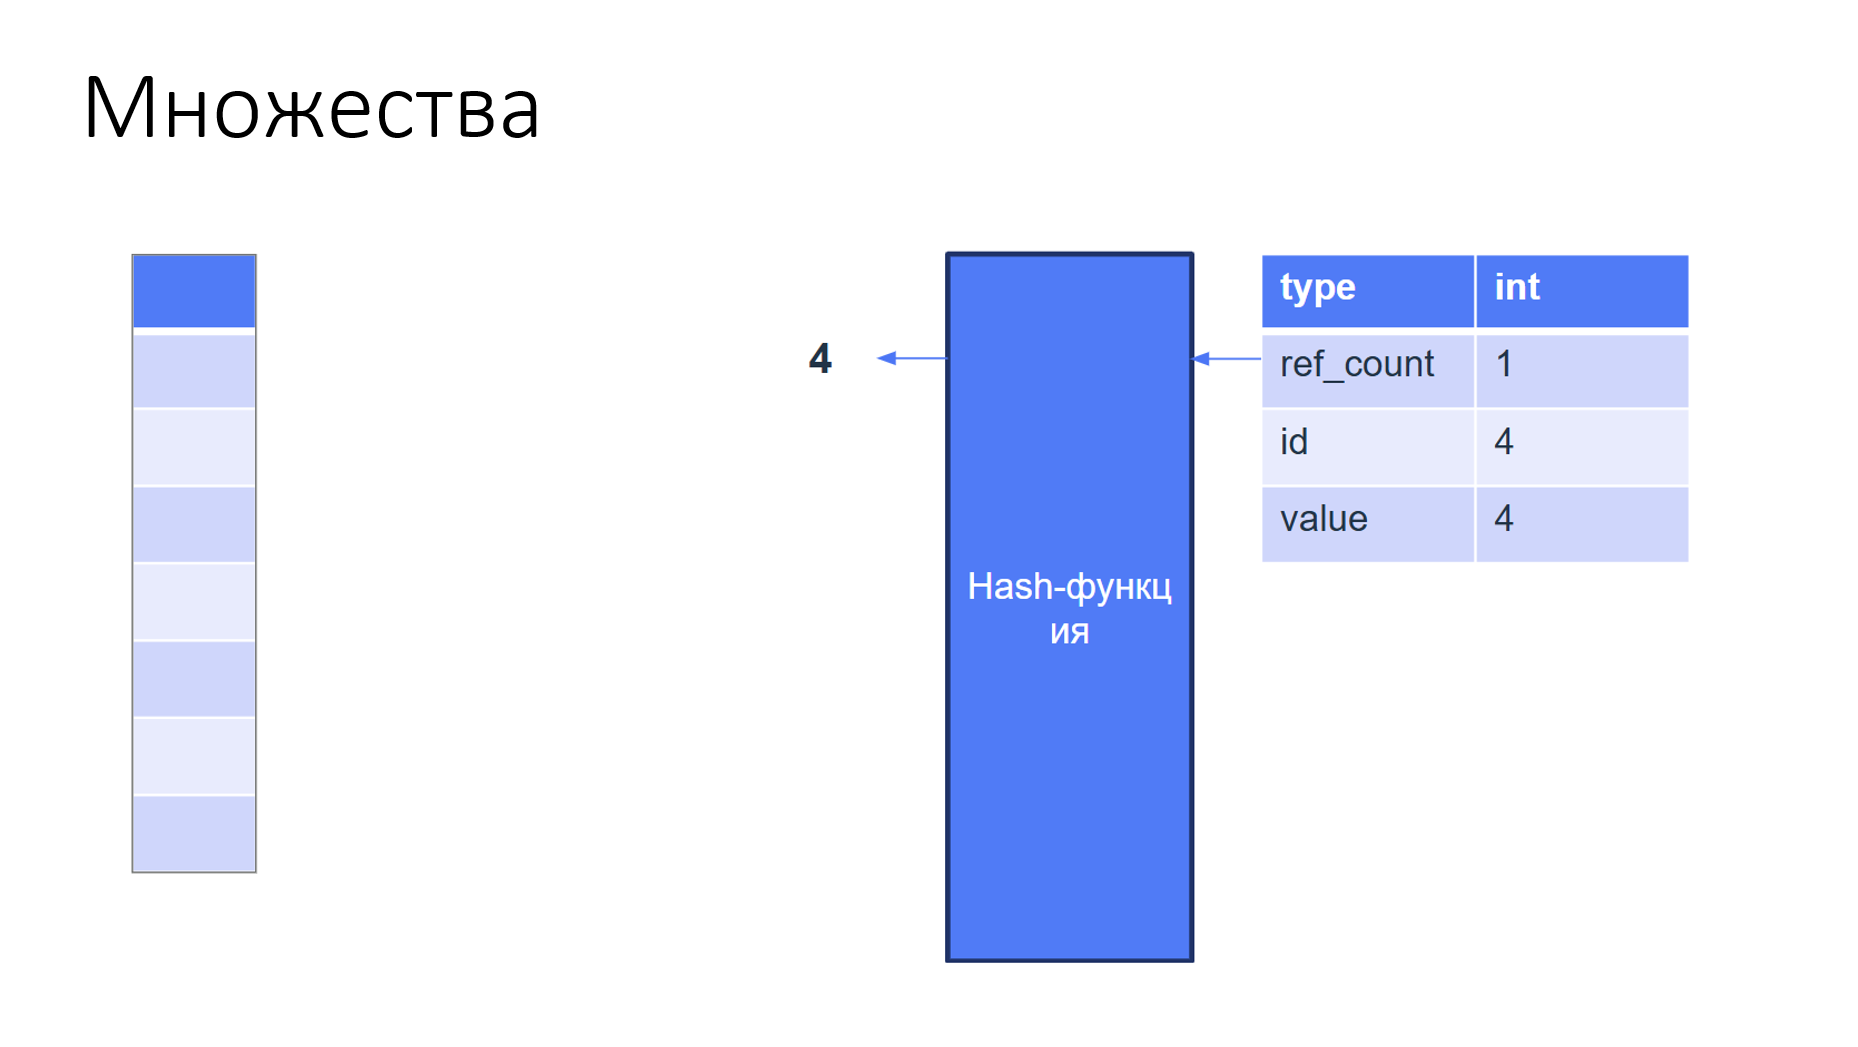
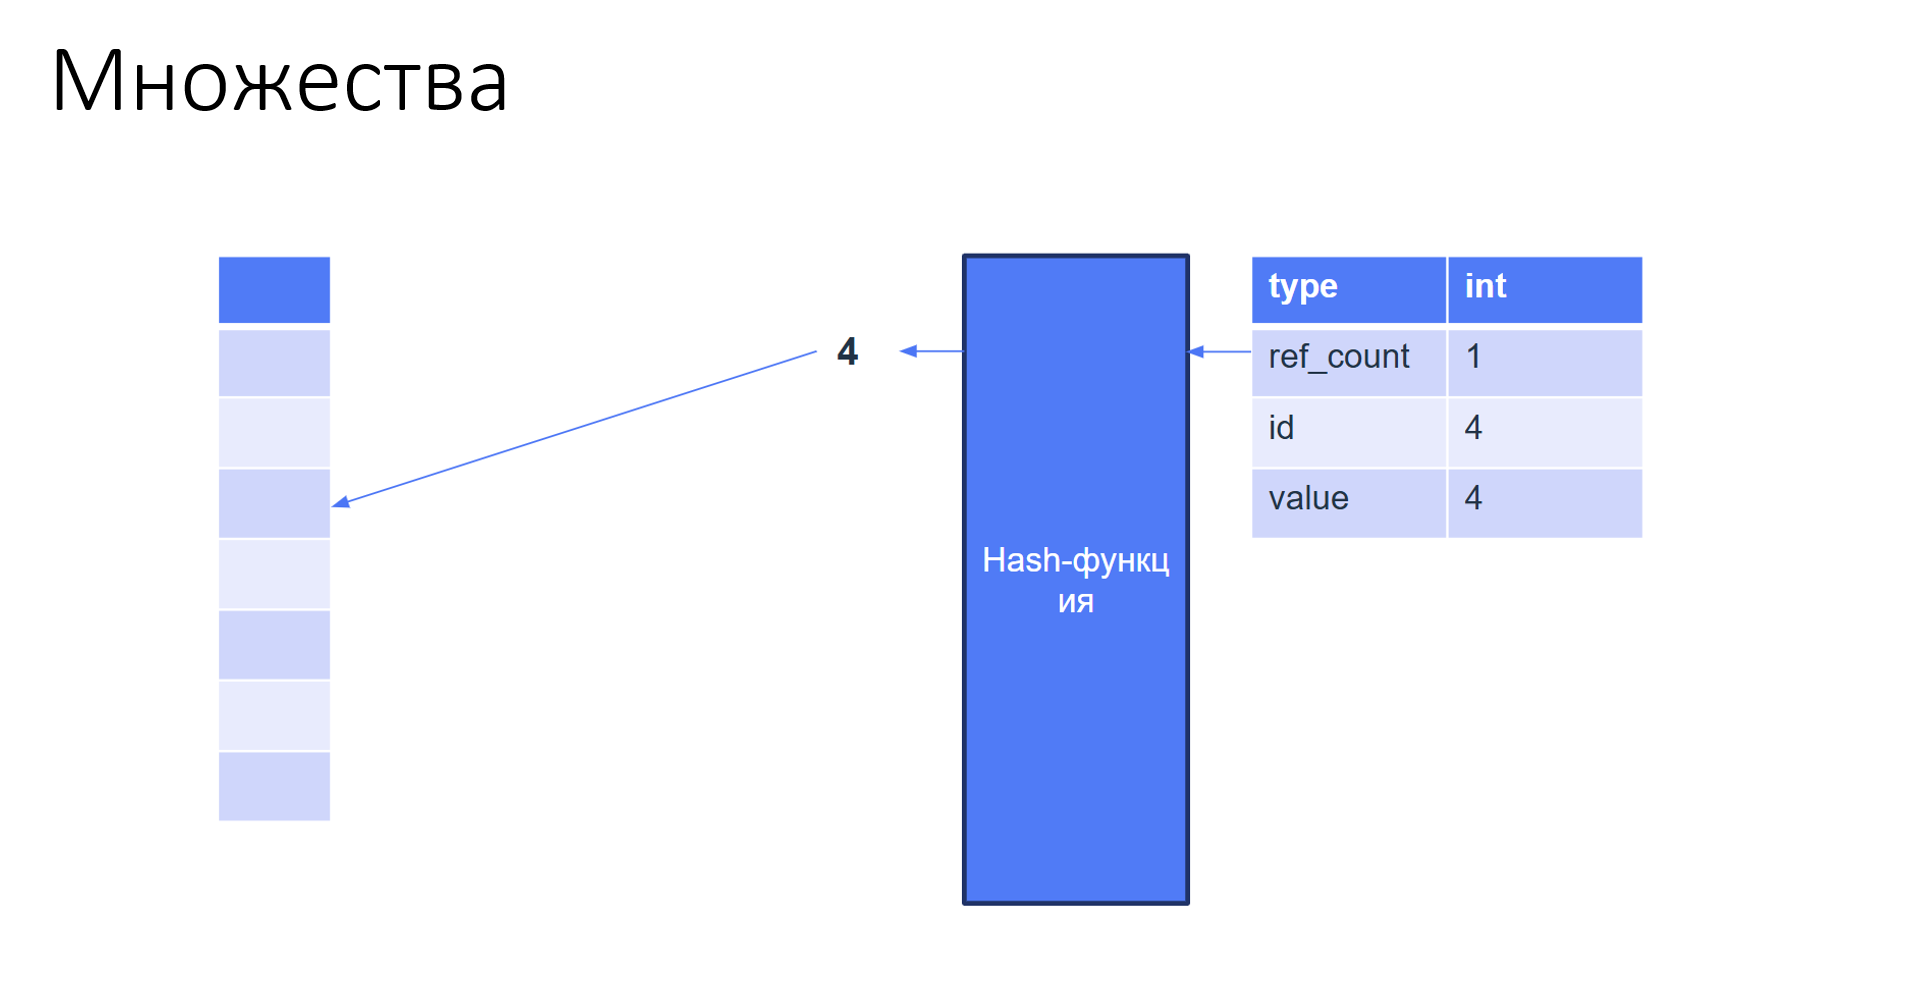
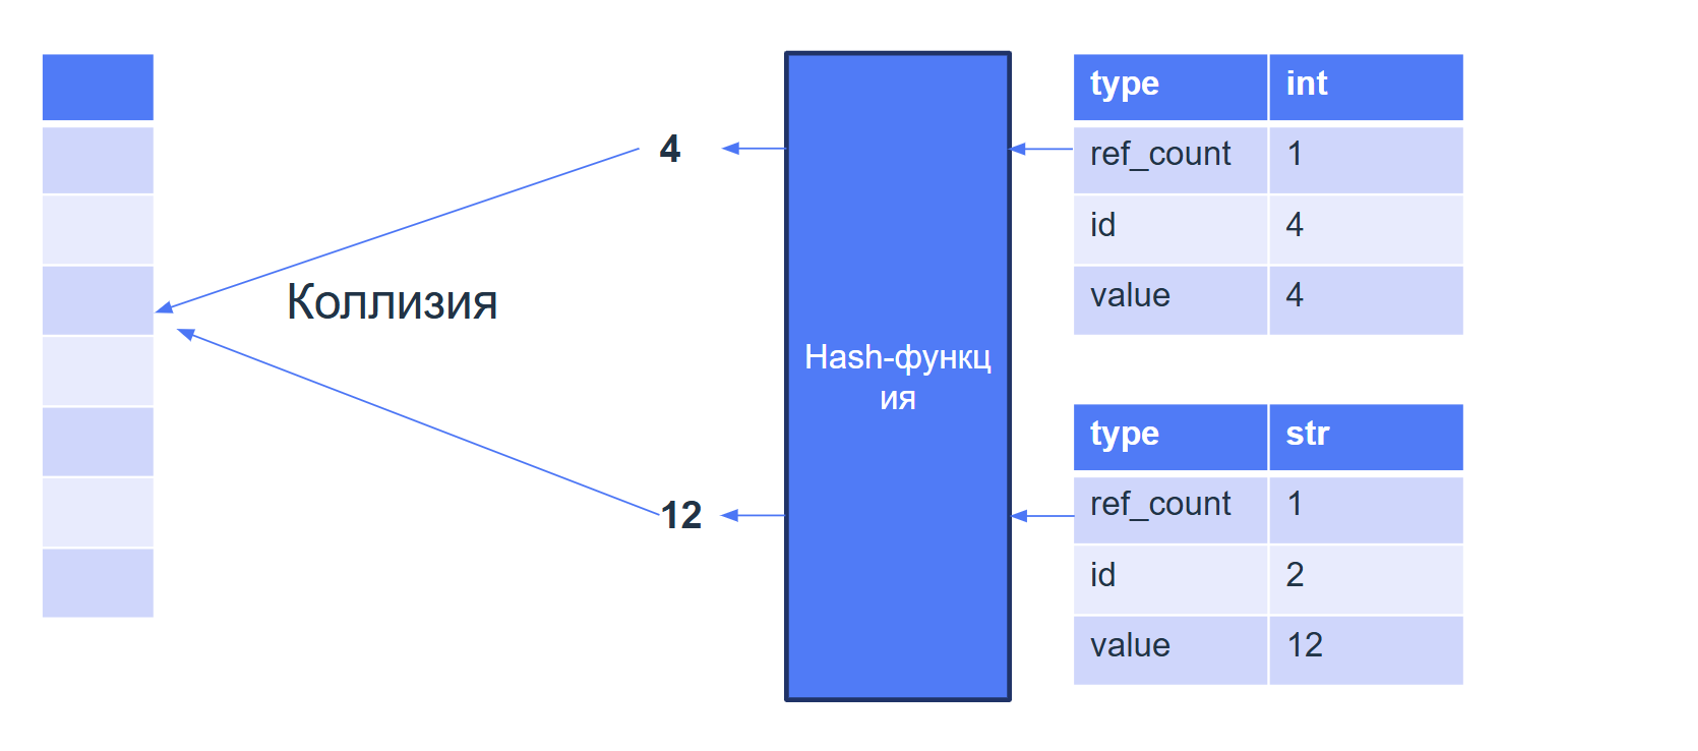

In [4]:
print({1: True, 1.0: False, True: "No idea"})

{1: 'No idea'}


Маркдаун на подумать
--

--

--

--

--

--

--

--


In [75]:
print({1: True, 1.0: False, True: "No idea"})

{1: 'No idea'}


### Решение: добавляем определение `__hash__`

У `set` и `dict` есть контракт: **равные объекты обязаны иметь равные хеши**. Старый хеш по умолчанию считался от `id(obj)`, и после нашего `__eq__` контракт был бы нарушен. Поэтому Python его просто убирает.

Чиним: хеш считаем от тех же полей, что участвуют в сравнении.

In [5]:
class Compound:
    """Химическое соединение."""

    def __init__(self, name: str, smiles: str) -> None:
        self.name = name
        self.smiles = smiles

    def __repr__(self) -> str:
        return f"Compound(name={self.name!r}, smiles={self.smiles!r})"

    def __eq__(self, other: object) -> bool:
        if not isinstance(other, Compound):
            return NotImplemented
        return self.smiles == other.smiles

    def __hash__(self) -> int:
        return hash(self.smiles)


aspirin = Compound("aspirin", "CC(=O)Oc1ccccc1C(=O)O")
acetylsalicylic_acid = Compound("acetylsalicylic acid", "CC(=O)Oc1ccccc1C(=O)O")
caffeine = Compound("caffeine", "Cn1cnc2c1c(=O)n(C)c(=O)n2C")
print({aspirin, acetylsalicylic_acid, caffeine})

{Compound(name='aspirin', smiles='CC(=O)Oc1ccccc1C(=O)O'), Compound(name='caffeine', smiles='Cn1cnc2c1c(=O)n(C)c(=O)n2C')}


### Ситуация: наш сет начал работать как-то сомнительно

In [6]:
library = {aspirin, caffeine}
aspirin.smiles = "CCO"

print(aspirin in library)  # не ищется
print(library)  # хотя он тут есть

False
{Compound(name='aspirin', smiles='CCO'), Compound(name='caffeine', smiles='Cn1cnc2c1c(=O)n(C)c(=O)n2C')}


Маркдаун на подумать
--

--

--

--

--

--

--

--


### Что случилось: мы посчитали адрес ячейки по новому значению `smiles`, а оно лежит в памяти по старому. Хеши не совпали, значит, такого значения там нет
Хешировать имеет смысл только **неизменяемые** поля и объекты.


## Ситуация: хотим коллекцию соединений, которая ведёт себя как встроенная

In [78]:
from collections.abc import Iterable, Iterator


class CompoundLibrary:
    """Библиотека соединений."""

    def __init__(self, compounds: Iterable[Compound]) -> None:
        self._compounds = list(compounds)

    def __iter__(self) -> Iterator[Compound]:
        yield from self._compounds


aspirin = Compound("aspirin", "CC(=O)Oc1ccccc1C(=O)O")
library = CompoundLibrary([aspirin, caffeine])

print(Compound("acetylsalicylic acid", "CC(=O)Oc1ccccc1C(=O)O") in library)
print([compound.name for compound in library])
print([compound.name for compound in library])  # и ещё раз: снова все

True
['aspirin', 'caffeine']
['aspirin', 'caffeine']


Мы реализовали `__iter__` через `yield`, поэтому **каждый** `for` получает новый генератор, и по библиотеке можно ходить сколько угодно раз. Вспомните `functions_demo`: генератор одноразовый, и `min`/`max` по одному и тому же генераторному выражению ломались. Итерируемый объект с `__iter__` эту проблему снимает.

### Ситуация: хотим использовать класс с контекстным менеджером
### Решение: определяем `__enter__` и `__exit__`

`with` гарантирует, что `__exit__` выполнится, даже если внутри блока произошло исключение. Так работают `open`, блокировки, соединения с базой.

In [7]:
import time


class Timer:
    """Замеряет время выполнения блока with."""

    def __enter__(self) -> "Timer":
        self.start = time.perf_counter()
        return self  # это значение попадёт в переменную после as

    def __exit__(self, exc_type, exc_value, traceback) -> bool:
        self.elapsed = time.perf_counter() - self.start
        print(f"{self.elapsed:.4f} s")
        return False  # False: исключение, если было, полетит дальше


with Timer() as timer:
    print(sum(range(1_000_000)))
# если внутри with упадёт исключение, время всё равно напечатается

499999500000
0.0122 s


## Принцип наименьшего удивления

Переопределять операторы стоит, только если их смысл **очевиден** в предметной области. Что должно вернуть `aspirin + caffeine`? Смесь? Новую молекулу? Ошибку? Если ответ неочевиден, лучше метод с понятным именем: `aspirin.mix_with(caffeine)`.

# Датаклассы

### Проблема: очень много однотипного простого кода
`Compound` выше содержит реализации `__init__`, `__repr__`, `__eq__`, `__hash__`, в которых очень легко ошибиться или что-то забыть. Например, добавить поле и забыть учесть его в `__eq__`.

### Решение: `@dataclass`
Позволяет генерировать эти методы по списку полей с аннотациями типов.

In [8]:
from dataclasses import FrozenInstanceError, dataclass, field
from typing import ClassVar


@dataclass(frozen=True, order=True)
class Compound:
    """Химическое соединение."""

    MAX_DRUG_LIKE_WEIGHT: ClassVar[float] = 500  # атрибут класса: не поле, в __init__, == и repr не попадает

    molecular_weight: float  # первое поле: по нему сортируем
    smiles: str
    name: str = field(default="", compare=False)  # название не участвует в операциях ==, < и hash

    def __post_init__(self) -> None:
        if self.molecular_weight <= 0:
            raise ValueError("Molecular weight must be positive")

    @property
    def is_drug_like_weight(self) -> bool:
        """Checks the molecular weight part of Lipinski's rule."""
        return self.molecular_weight <= self.MAX_DRUG_LIKE_WEIGHT


aspirin = Compound(
    molecular_weight=180.16,
    smiles="CC(=O)Oc1ccccc1C(=O)O",
    name="aspirin",
)
acetylsalicylic_acid = Compound(
    molecular_weight=180.16,
    smiles="CC(=O)Oc1ccccc1C(=O)O",
    name="acetylsalicylic acid",
)
caffeine = Compound(
    molecular_weight=194.19,
    smiles="Cn1cnc2c1c(=O)n(C)c(=O)n2C",
    name="caffeine",
)

print(aspirin)  # __repr__
print(aspirin == acetylsalicylic_acid)  # True: название не сравнивается
print({aspirin, acetylsalicylic_acid})  # frozen -> хешируемый
print(sorted([caffeine, aspirin]))
print(aspirin.is_drug_like_weight, Compound.MAX_DRUG_LIKE_WEIGHT)  # порог общий для всех соединений

try:
    aspirin.smiles = "CCO"
except FrozenInstanceError as error:
    print(error)

try:
    Compound(molecular_weight=-1, smiles="C")
except ValueError as error:
    print(error)

Compound(molecular_weight=180.16, smiles='CC(=O)Oc1ccccc1C(=O)O', name='aspirin')
True
{Compound(molecular_weight=180.16, smiles='CC(=O)Oc1ccccc1C(=O)O', name='aspirin')}
[Compound(molecular_weight=180.16, smiles='CC(=O)Oc1ccccc1C(=O)O', name='aspirin'), Compound(molecular_weight=194.19, smiles='Cn1cnc2c1c(=O)n(C)c(=O)n2C', name='caffeine')]
True 500
cannot assign to field 'smiles'
Molecular weight must be positive


In [9]:
@dataclass
class Well:
    row: str
    column: int


well = Well("A", 1)
well.colunm = 2  # опечатка: молча создался новый атрибут
print(well)

Well(row='A', column=1)


In [10]:
@dataclass(slots=True)
class Well:
    row: str
    column: int


well = Well("A", 1)
well.compounds = ["aspirin"]


AttributeError: 'Well' object has no attribute 'compounds'

In [11]:
@dataclass(slots=True)
class Well:
    row: str
    column: int
    compounds: list[str] = field(default_factory=list)


well = Well("A", 1)
well.compounds.append("aspirin")
well.compounds

['aspirin']

# Как объекты связаны друг с другом

| Отношение | Смысл | Кто управляет жизнью части | В UML |
|---|---|---|---|
| **Ассоциация** | «использует» | никто, связь временная | пунктирная стрелка `⇢` |
| **Агрегация** | «имеет, но не владеет» | внешний код | пустой ромб у целого `◇—` |
| **Композиция** | «состоит из, владеет» | сам объект | закрашенный ромб у целого `◆—` |
| **Наследование** | «является» | – | пустой треугольник у родителя `—▷` |

Разберём все четыре на одной сцене: плейты, веллы, эксперименты и плейт-ридер.

![UML-диаграмма классов: эксперимент, планшет, лунка, ридер и 384-луночный планшет](images/plates_uml.svg)

**UML** (Unified Modeling Language) – стандартный язык схем для описания программ. Диаграмма классов показывает классы (имя, атрибуты, методы) и связи между ними.

То, что мы называем ассоциацией – «получил объект аргументом и не хранит», – в UML называется **зависимостью** и рисуется пунктирной стрелкой. Сплошная линия-ассоциация в UML означает постоянную связь, когда объект хранит ссылку на другой. Агрегация и композиция – частные случаи такой связи.

## Как понять, какая связь

1. **Объект хранит ссылку на другой или получает его только на время вызова?** Только в вызове – ассоциация.
2. **Кто создаёт часть?** Сам объект – скорее композиция. Передают снаружи – агрегация.
3. **Может ли часть существовать без целого?** Нет – композиция. Да – агрегация.
4. **Может ли часть принадлежать нескольким целым сразу?** Да – точно не композиция.
5. **Можно ли сказать «X является Y» и подставить X везде вместо Y?** Да – наследование.

Граница между агрегацией и композицией бывает спорной, и это нормально: важнее понимать, кто за что отвечает, чем выбрать «правильное» слово.

## Агрегация: эксперимент и планшеты

Эксперимент связан с плейтами, но плейты могут существовать и без него. Один контрольный планшет можно использовать в нескольких экспериментах, и он переживёт любой из них.

In [14]:
class Experiment:
    """Эксперимент над набором планшетов."""

    def __init__(self, name: str, plates: list["Plate"]) -> None:
        self.name = name
        self.plates = plates  # не создаёт, а получает

## Композиция: плейт и веллы

Веллы – неотъемлемая часть плейта. Вне плейта их не существует.

In [15]:
@dataclass
class Well:
    row: str
    column: int
    compound: Compound | None = None


class Plate:
    """Планшет: общий код для лунок. Размеры задаёт конкретный тип планшета."""

    ROWS: ClassVar[str]  # только объявлены: значений у общего планшета нет
    COLUMNS: ClassVar[range]

    def __init__(self, plate_id: str) -> None:
        self.plate_id = plate_id
        self._wells = [
            Well(row, column)
            for row in self.ROWS
            for column in self.COLUMNS
        ]

    def fill(self, row: str, column: int, compound: Compound) -> None:
        for well in self._wells:
            if (well.row, well.column) == (row, column):
                well.compound = compound

    def filled_wells(self) -> dict[str, Compound]:
        return {f"{well.row}{well.column}": well.compound for well in self._wells if well.compound is not None}

    def __len__(self) -> int:
        return len(self._wells)

# Наследование: спецификация каждого планшета
`Plate96` и `Plate384` **являются** планшетами. Общий код (создание лунок, заполнение, поиск заполненных) живёт в `Plate`, а размеры задаёт каждый наследник. Ридер работает с любым из них без изменений.

In [16]:
class Plate96(Plate):
    """96-луночный планшет."""

    ROWS = "ABCDEFGH"
    COLUMNS = range(1, 13)


class Plate384(Plate):
    """384-луночный планшет."""

    ROWS = "ABCDEFGHIJKLMNOP"
    COLUMNS = range(1, 25)


plate = Plate96("P001")
plate.fill("A", 1, aspirin)
plate.fill("A", 2, caffeine)
big_plate = Plate384("P384")
big_plate.fill("P", 24, aspirin)

In [17]:
control = Plate96("CONTROL")
screening = Experiment("screening", [plate, control])
follow_up = Experiment("follow-up", [control])  # тот же контрольный планшет

del screening
print(control.plate_id, len(follow_up.plates))  # эксперимента нет, планшет жив

CONTROL 1


## Ассоциация: ридер и планшет

Ридер **пользуется** планшетом только на время измерения: получает его аргументом и ничего о нём не запоминает.

In [18]:
class PlateReader:
    """Планшетный ридер: измеряет сигнал в заполненных лунках."""

    def read(self, plate: Plate) -> dict[str, float]:
        return {position: 0.8 for position in plate.filled_wells()}  # сигнал условный


reader = PlateReader()
print(reader.read(plate))
print(hasattr(reader, "plate"))  # ридер не хранит планшет

{'A1': 0.8, 'A2': 0.8}
False


**В Python нет синтаксической разницы между агрегацией и композицией.** Это вопрос дизайна: кто создаёт часть и кто отвечает за её жизненный цикл.

* Агрегация даёт гибкость: части можно подменить (например, в тестах) и переиспользовать.
* Композиция даёт контроль: объект гарантирует, что его части в порядке, потому что никто другой их не трогает.

## Упражнение: какая здесь связь?

1. Дом и его комнаты
2. Университет и студенты
3. Покупатель и банкомат, в котором он снимает деньги
4. Плейлист и песни в нём
5. Кот и животное
6. Пингвин и птица

# Место на подумать
--

--

--

--

--

--

--

--

--

--

**Ответы**

1. **Композиция:** комнаты не существуют без дома и не переходят в другой дом.
2. **Агрегация:** студенты существуют и без университета и могут перевестись в другой.
3. **Ассоциация:** покупатель пользуется банкоматом только во время операции и не «хранит» его.
4. **Агрегация:** песни существуют сами по себе, и одна песня может быть в нескольких плейлистах.
5. **Наследование:** кот является животным.
6. **Ловушка:** лучше держать как две не связанные напрямую сущности.

# Исключения: хороший пример наследования

> **Углубляем: наследование (как надо).** Иерархия, в которой наследование работает идеально. И заодно вспомним, как правильно обрабатывать ошибки.

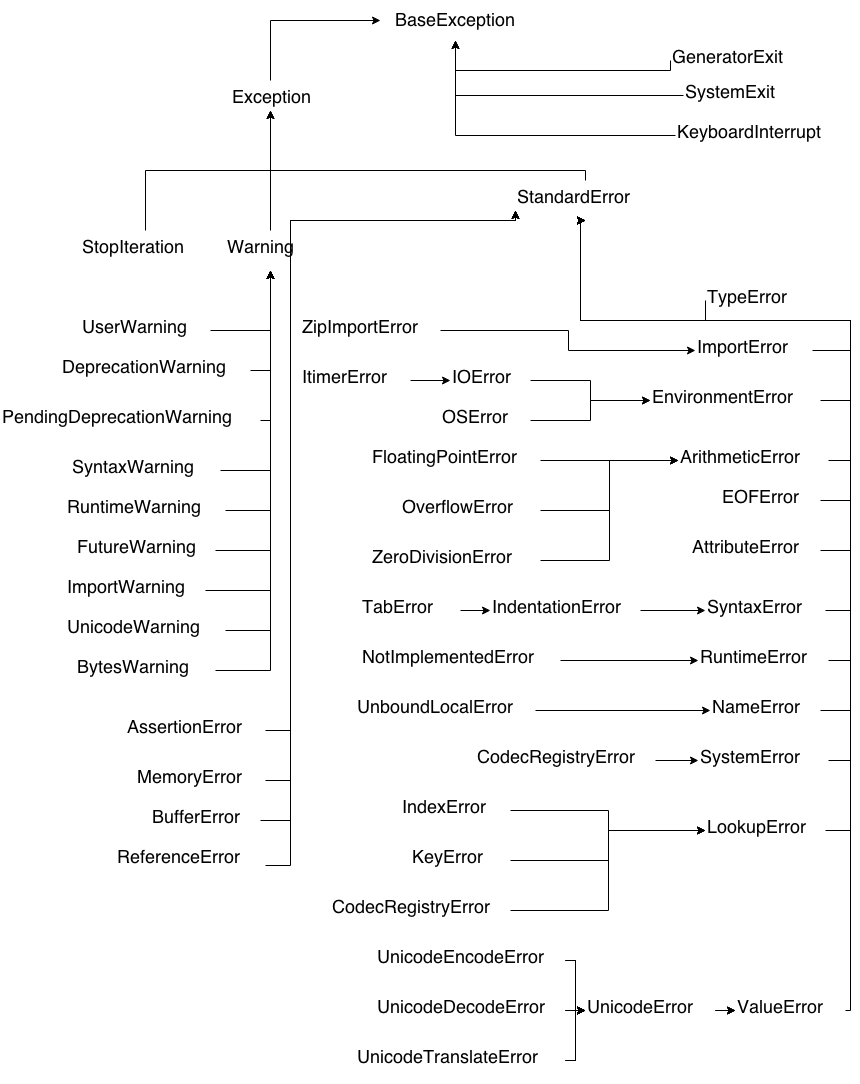

Все исключения в Python – классы, выстроенные в иерархию:

```
BaseException
├── KeyboardInterrupt, SystemExit   ← не ошибки программы, а сигналы «остановись»
└── Exception                       ← всё, что мы обычно ловим
    ├── ValueError
    ├── TypeError
    ├── LookupError
    │   ├── KeyError
    │   └── IndexError
    └── OSError
        ├── FileNotFoundError
        └── PermissionError
```

Почему это хорошее наследование:
* отношение «является» выполняется честно: `KeyError` **является** `LookupError`;
* наследник везде может заменить родителя (L из SOLID): код, который ловит `LookupError`, корректно обработает и `KeyError`, и `IndexError`;
* иерархия неглубокая, и наследники почти не переопределяют поведение: они уточняют **смысл** ошибки.

`except` работает через `isinstance`, поэтому ловить можно сразу целую ветку иерархии:

In [19]:
compound = {"name": "aspirin", "smiles": "CC(=O)Oc1ccccc1C(=O)O"}
plate_ids = ["P001", "P002"]

try:
    compound["molecular_weight"]  # такого ключа нет -> KeyError
except LookupError as error:
    print("не нашли:", repr(error))

try:
    plate_ids[5]  # такого индекса нет -> IndexError
except LookupError as error:
    print("не нашли:", repr(error))

print(issubclass(KeyError, LookupError), issubclass(IndexError, LookupError))

не нашли: KeyError('molecular_weight')
не нашли: IndexError('list index out of range')
True True


## Своя иерархия исключений

У библиотеки или пайплайна стоит завести **один базовый класс** ошибок и наследовать от него конкретные. Тогда вызывающий код выбирает, насколько подробно реагировать: ловить конкретную ошибку или всё, что относится к нашему коду, разом.

Наследуемся от `Exception`, а не от `BaseException`: иначе `except Exception` не поймает нашу ошибку, а `except BaseException` заодно поймает Ctrl+C.

In [22]:
class PipelineError(Exception):
    """Базовая ошибка пайплайна."""
    pass


class InvalidSmilesError(PipelineError):
    """SMILES не удалось разобрать."""

    def __init__(self, mol_id: str, smiles: str) -> None:
        super().__init__(f"{mol_id}: invalid SMILES {smiles!r}")
        self.mol_id = mol_id  # контекст ошибки доступен как атрибуты
        self.smiles = smiles


class SourceError(PipelineError):
    """Не удалось получить данные из источника."""
    pass

try:
    raise InvalidSmilesError("M042", "C1CC")
except InvalidSmilesError as error:
    print(error, "|", error.mol_id)

try:
    raise SourceError("REINVENT exited with code 1")
except PipelineError as error:  # всё, что относится к пайплайну
    print(type(error).__name__, error)

M042: invalid SMILES 'C1CC' | M042
SourceError REINVENT exited with code 1


## Как правильно обрабатывать исключения

### 1. Ловим конкретное, а не всё подряд

`except:` и `except Exception: pass` глотают **любые** ошибки, включая ошибки в нашем собственном коде.

In [20]:
def parse_concentration(text: str) -> float | None:
    try:
        return float(txt)  # опечатка в имени переменной
    except Exception:
        return None


print(parse_concentration("10"))  # Никогда не узнаем про баг


def parse_concentration(text: str) -> float | None:
    try:
        return float(txt)
    except ValueError:  # ловим только то, что ожидаем: строку, которая не число
        return None  # в идеале ещё и логируем, что что-то пошло не так


try:
    parse_concentration("10")
except NameError as error:
    print("баг виден сразу:", error)

None
баг виден сразу: name 'txt' is not defined


### 2. Порядок `except`: от частного к общему

Python проверяет блоки `except` сверху вниз и заходит в первый подходящий. Если родитель стоит выше наследника, до наследника очередь не дойдёт никогда.

In [ ]:
try:
    {}["MW"]
except LookupError:
    print("сработал LookupError")
except KeyError:  # недостижим: KeyError уже пойман строкой выше
    print("сработал KeyError")

### 3. Переупаковка: `raise ... from ...`

Низкоуровневую ошибку (`FileNotFoundError`, `subprocess.CalledProcessError`) часто стоит обернуть в ошибку нашей предметной области. `from error` сохраняет исходную причину в `__cause__`, и в traceback видны обе.

Если ошибку нужно только залогировать и пробросить дальше без изменений, пишем `raise` без аргументов.

In [23]:
def read_source(path: str) -> str:
    try:
        with open(path, encoding="utf-8") as file:
            return file.read()
    except FileNotFoundError as error:
        raise SourceError(f"cannot read {path}") from error


try:
    read_source("missing.csv")
except SourceError as error:
    print(error, "| cause:", repr(error.__cause__))

cannot read missing.csv | cause: FileNotFoundError(2, 'No such file or directory')


### 4. Исключение или `None`?

`Molecule.from_row` в пайплайне возвращает `None`, если SMILES невалидный. Альтернатива – бросить `InvalidSmilesError`.

* `None` удобен, когда «не получилось» – нормальный, ожидаемый исход (часть молекул в данных всегда битая), и вызывающий код сразу его проверяет.
* Исключение лучше, когда ошибку нельзя молча пропустить, или её нужно обработать далеко от места, где она возникла, или к ней нужен контекст (`mol_id`, `smiles`).

**Памятка:**
* ловим конкретные исключения, а не `Exception`;
* никогда не `except: pass`;
* `except` – от частного к общему;
* свои ошибки – от общего базового класса, который наследуется от `Exception`;
* переупаковываем через `raise ... from error`, пробрасываем через голый `raise`.

# Множественное наследование и MRO

До сих пор у каждого наследника был один родитель: `Plate96(Plate)`. Но иногда хочется взять поведение сразу у нескольких классов. Например, планшет со штрихкодом – это и планшет, и объект, который умеет печатать свою этикетку. Python это позволяет: родителей можно перечислить через запятую.

```python
class BarcodedPlate(Plate96, Labeled):
    ...
```

Сразу возникает вопрос: если метод с одним и тем же именем есть у нескольких родителей, какой из них вызовется? Ответ даёт **MRO** (method resolution order): у каждого класса есть `__mro__` – порядок, в котором Python ищет атрибуты.

Начнём с простой цепочки, где родитель один:

![Цепочка: object, A, B(A), C(B)](images/mro_chain.svg)

In [24]:
class A:
    def hello(self) -> str:
        return "A"


class B(A):
    def hello(self) -> str:
        return "B"


class C(B):
    pass


print(A().hello(), B().hello(), C().hello())

A B B


Как Python ищет атрибут или метод:

1. сначала в самом объекте – среди атрибутов, присвоенных через `self.…`;
2. потом в классах по порядку **MRO** (method resolution order) и берёт **первое** найденное;
3. если не нашёл ни в одном классе, включая `object`, – `AttributeError`.

Порядок MRO у каждого класса вычисляется один раз, при его создании, и лежит в `Class.__mro__`. Строится он по трём правилам:

* **наследник всегда раньше своих родителей**;
* **родители идут в том порядке, в котором перечислены в скобках** – слева направо;
* Python не заходит в класс, пока не прошёл всех его наследников из этой иерархии. Поэтому сначала проходится ветка первого родителя, но до общего с другими ветками предка дело доходит только в самом конце.

`object` – предок всех классов, поэтому он всегда последний. Если правила нельзя выполнить одновременно, Python отказывается создавать класс и бросает `TypeError`.

Пока родитель один, всё это сводится к простому «вверх по цепочке». Интересное начинается, когда родителей несколько. Классический пример – ромб:

![Ромб: A, B(A), C(A), D(B, C)](images/mro_diamond.svg)

In [25]:
class A:
    def hello(self) -> None:
        print("A")


class B(A):
    def hello(self) -> None:
        print("B")


class C(A):
    def hello(self) -> None:
        print("C")


class D(B, C):
    pass


D().hello()
print([cls.__name__ for cls in D.__mro__])

B
['D', 'B', 'C', 'A', 'object']


Порядок родителей в скобках меняет порядок поиска:

![Тот же ромб, но E(C, B)](images/mro_diamond_reversed.svg)

In [26]:
class E(C, B):
    pass

E().hello()
print([cls.__name__ for cls in E.__mro__])

C
['E', 'C', 'B', 'A', 'object']


А если два правила противоречат друг другу, класс создать нельзя:

In [27]:
class A:
    def hello(self) -> None:
        print("A")


class B(A):
    def hello(self) -> None:
        print("B")

try:
    class X(A, B):
        pass
except TypeError as error:
    print(error)

Cannot create a consistent method resolution
order (MRO) for bases A, B


![Конфликт: X(B, C), Y(C, B), Z(X, Y)](images/mro_conflict.svg)

In [28]:
class X(B, C):
    pass


class Y(C, B):
    pass


try:
    class Z(X, Y):  # X требует B раньше C, а Y – C раньше B
        pass
except TypeError as error:
    print(error)

Cannot create a consistent method resolution
order (MRO) for bases B, C


## Вопрос

![Иерархия: A, B(A), C(A), D(B), F(B), E(D, F, C)](images/mro_question.svg)

# Место на подумать
--

--

--

--

--

--

--

--

--

--

**Ответ**

![Порядок поиска: E, D, F, B, C, A, object](images/mro_answer.svg)

Проверим:

In [29]:
class A: pass
class B(A): pass
class C(A): pass
class D(B): pass
class F(B): pass
class E(D, F, C): pass


print([cls.__name__ for cls in E.__mro__])

['E', 'D', 'F', 'B', 'C', 'A', 'object']


# Интерфейсы: ABC и Protocol

На прошлой паре мы опирались на утиную типизацию: «если у объекта есть `describe()`, он подходит». Но это обещание нигде не записано:
* опечатка в имени метода всплывёт только при вызове;
* mypy и PyCharm не могут проверить, что объект подходит;
* чтобы понять, что обязан уметь новый класс, нужно читать код, который его вызывает.

Python даёт два способа записать контракт формально.

## ABC: абстрактный базовый класс

Наследуемся от `ABC`, помечаем обязательные методы `@abstractmethod`. Создать экземпляр класса, у которого реализованы не все абстрактные методы, нельзя. Ошибка возникает **при создании объекта**, а не при объявлении класса.

ABC особенно полезен, когда у наследников есть **общий код**. Классический приём – **шаблонный метод** (это паттерн, вернёмся к нему позже): родитель задаёт алгоритм целиком, а наследники заполняют отдельные шаги.

In [31]:
from abc import ABC, abstractmethod


class Assay(ABC):
    """Биологический тест: алгоритм общий, измерение у каждого своё."""

    name: str
    threshold: float

    def run(self, sample: str) -> str:  # шаблонный метод
        value = self._measure(sample)
        verdict = "active" if value > self.threshold else "inactive"
        return f"{self.name}: {sample} -> {value} ({verdict})"

    @abstractmethod
    def _measure(self, sample: str) -> float:
        """Шаг, который реализует каждый наследник."""


class FluorescenceAssay(Assay):
    name = "Fluorescence"
    threshold = 0.5

    def _measure(self, sample: str) -> float:
        return 0.8


class BrokenAssay(Assay):  # класс объявить можно
    name = "Broken"
    threshold = 0.0


print(FluorescenceAssay().run("aspirin"))
try:
    Assay()  # а создать объект нельзя
except TypeError as error:
    print(error)

Fluorescence: aspirin -> 0.8 (active)
Can't instantiate abstract class Assay without an implementation for abstract method '_measure'


## Protocol: структурная типизация

`ABC` – **номинальная** типизация: класс подходит, только если явно унаследован от `Assay`.

`Protocol` – **структурная** типизация: класс подходит, если у него есть нужные методы, наследоваться не надо. Это та же утиная типизация, только записанная так, что её проверяют mypy и PyCharm.

In [32]:
from typing import Protocol, runtime_checkable


@runtime_checkable
class Describable(Protocol):
    """Всё, что умеет себя описать."""

    def describe(self) -> str: ...


class Drug:
    def __init__(self, name: str) -> None:
        self.name = name

    def describe(self) -> str:
        return f"Drug {self.name}"


class Student:  # никакого отношения к Drug, и от Describable не наследуется
    def describe(self) -> str:
        return "Проблема очень сложная, но мы её решим"


def print_all(items: list[Describable]) -> None:
    for item in items:
        print(item.describe())


print_all([Drug("ibuprofen"), Student()])  # mypy доволен
print(isinstance(Student(), Describable), isinstance(42, Describable))

Drug ibuprofen
Проблема очень сложная, но мы её решим
True False


`@runtime_checkable` разрешает `isinstance`, но проверяет **только наличие методов**, а не их сигнатуры. Полная проверка – в mypy.

| | `ABC` | `Protocol` |
|---|---|---|
| Как класс начинает подходить | явно наследуется | достаточно иметь нужные методы |
| Общий код для наследников | да (шаблонный метод) | обычно нет, только контракт |
| Проверка | при создании объекта | mypy / PyCharm; `isinstance` с `@runtime_checkable` |
| Чужие классы, которые нельзя менять | не подходят | подходят, если совпадает структура |
| Когда брать | есть общая логика и иерархия | нужен только контракт: «что мне нужно от объекта» |

# Миксины

**Задача**: одинаковая возможность (например, сериализация в JSON) нужна классам из **разных** иерархий. Общего родителя у них нет и быть не должно.

**Миксин** – маленький класс с одной возможностью, который подмешивают через множественное наследование. Сам по себе он не используется.

In [33]:
import json


class JsonMixin:
    """Умеет сериализовать атрибуты объекта в JSON."""

    def to_json(self) -> str:
        return json.dumps(vars(self), ensure_ascii=False)


class ReprMixin:
    """Генерирует __repr__ по атрибутам объекта."""

    def __repr__(self) -> str:
        fields = ", ".join(f"{key}={value!r}" for key, value in vars(self).items())
        return f"{type(self).__name__}({fields})"


class Reagent(ReprMixin, JsonMixin):
    def __init__(self, name: str, supplier: str) -> None:
        self.name = name
        self.supplier = supplier


class Aliquot(ReprMixin, JsonMixin):
    def __init__(self, sample: str, volume_ul: float) -> None:
        self.sample = sample
        self.volume_ul = volume_ul


print(Reagent("DMSO", "Sigma"), Reagent("DMSO", "Sigma").to_json())
print(Aliquot("plasma", 50.0), Aliquot("plasma", 50.0).to_json())

Reagent(name='DMSO', supplier='Sigma') {"name": "DMSO", "supplier": "Sigma"}
Aliquot(sample='plasma', volume_ul=50.0) {"sample": "plasma", "volume_ul": 50.0}


## Правила хорошего миксина

* одна возможность на миксин;
* максимально общий функционал;
* имя заканчивается на `Mixin`;
* по возможности без своего состояния и своего `__init__`; если `__init__` нужен – кооперативный, с `**kwargs`;
* ставится левее основного класса;
* сам по себе не используется: `JsonMixin()` бессмыслен;
* миксин, который **меняет** поведение метода, должен стоять **левее** класса, поведение которого он меняет. Иначе он молча не сработает.

Если миксинов становится много и они зависят друг от друга, это повод вернуться к композиции.

# Как понять, что наша система классов хорошая: SOLID

Мы научились делать классы, связывать их, наследовать и записывать контракты. Но как понять, что получившаяся система классов хорошая? Что её будет легко менять через полгода?

Две базовые эвристики:
* **высокая связность** (cohesion): всё внутри класса работает на одну задачу;
* **слабая сцепленность** (coupling): классы мало знают о внутреннем устройстве друг друга.

**SOLID** – пять принципов, которые детализируют эти идеи. Их собрал Роберт Мартин, а аббревиатуру придумал Майкл Физерс.

| Принцип | Формулировка | Признак нарушения |
|---|---|---|
| **S** – Single Responsibility | у класса одна причина для изменения | методы класса делятся на группы, которые меняются по разным причинам |
| **O** – Open/Closed | новое поведение добавляется новым кодом, а не правкой старого | каждое новое требование – ещё одна ветка `if/elif` в старом коде |
| **L** – Liskov Substitution | наследник работает везде, где работает родитель | наследник бросает `NotImplementedError` на унаследованный метод |
| **I** – Interface Segregation | лучше несколько маленьких интерфейсов, чем один большой | класс вынужден реализовывать методы, которые ему не нужны |
| **D** – Dependency Inversion | высокоуровневый код зависит от абстракции, а не от деталей | класс сам создаёт конкретные объекты, от которых зависит |

## S – одна зона ответственности

In [ ]:
class User:  # нарушение: три причины для изменения
    def __init__(self, name: str, email: str) -> None:
        self.name = name
        self.email = email

    def save_to_database(self) -> None:  # меняется, если сменили базу данных
        ...

    def send_welcome_email(self) -> None:  # меняется, если сменили почтовый сервис
        ...


# исправление: у каждой части своя причина для изменения
class User:
    def __init__(self, name: str, email: str) -> None:
        self.name = name
        self.email = email


class UserRepository:
    def save(self, user: User) -> None: ...


class EmailSender:
    def send_welcome(self, user: User) -> None: ...

## O – расширяем, а не правим

Новая скидка не должна требовать правки работающего класса.

In [34]:
class Checkout:  # нарушение: каждая новая скидка – правка этого класса
    def total(self, price: float, customer: str) -> float:
        if customer == "student":
            return price * 0.8
        return price


# исправление: новая скидка – новый наследник, Checkout не трогаем
class Discount:
    def apply(self, price: float) -> float:
        return price


class StudentDiscount(Discount):
    def apply(self, price: float) -> float:
        return price * 0.8


class Checkout:
    def total(self, price: float, discount: Discount) -> float:
        return discount.apply(price)


print(
    Checkout().total(100, Discount()),
    Checkout().total(100, StudentDiscount()),
)

100 80.0


## L – наследник не ломает обещаний родителя

In [ ]:
class Bird:
    def fly(self) -> str:
        return "летит"


class Penguin(Bird):
    def fly(self) -> str:
        raise NotImplementedError("пингвины не летают")


def let_all_fly(birds: list[Bird]) -> None:
    for bird in birds:
        print(bird.fly())


try:
    let_all_fly([Bird(), Penguin()])
except NotImplementedError as error:
    print(error)

`let_all_fly` честно работает с `Bird`, и по типам `Penguin` подходит. Но подставить его вместо `Bird` нельзя: он ломает обещание родителя «я умею летать». Исправление – не наследовать пингвина от птицы.

Признаки нарушения:
* наследник бросает исключение на унаследованный метод;
* наследник требует больше (сужает допустимые аргументы) или обещает меньше (возвращает другой тип);
* вызывающему коду приходится проверять `isinstance(x, Penguin)`, чтобы не упасть.

## I – не заставляем реализовывать лишнее

«Интерфейс на всё» вынуждает реализовывать ненужные методы и в итоге снова нарушать L:

In [35]:
class Machine(ABC):  # нарушение: «интерфейс на всё»
    @abstractmethod
    def print_document(self, text: str) -> None: ...

    @abstractmethod
    def scan(self) -> str: ...

    @abstractmethod
    def fax(self, number: str) -> None: ...


class OldPrinter(Machine):  # умеет только печатать, но обязан реализовать всё
    def print_document(self, text: str) -> None:
        print("печатаю:", text)

    def scan(self) -> str:
        raise NotImplementedError("не умею сканировать")  # и снова нарушение L

    def fax(self, number: str) -> None:
        raise NotImplementedError("не умею отправлять факс")


# исправление: маленькие протоколы, функция требует только то, что ей нужно
class Printer(Protocol):
    def print_document(self, text: str) -> None: ...


def print_report(printer: Printer) -> None:
    printer.print_document("отчёт")


print_report(OldPrinter())

печатаю: отчёт


## D – зависим от абстракции

Магазин – главное в программе, способ уведомления – деталь. Если `Shop` сам создаёт `EmailNotifier`, то перейти на SMS можно только переписав `Shop`. Если же `Shop` зависит от общего `Notifier`, то способ уведомления выбирает тот, кто создаёт магазин, а сам `Shop` не меняется.

In [ ]:
class EmailNotifier:
    def send(self, text: str) -> None:
        print("email:", text)


class Shop:  # нарушение: магазин намертво привязан к email
    def checkout(self) -> None:
        EmailNotifier().send("Заказ оформлен")


# исправление: магазин знает только «какой-то уведомитель», а какой именно – решают снаружи
class Notifier:
    def send(self, text: str) -> None: ...


class EmailNotifier(Notifier):
    def send(self, text: str) -> None:
        print("email:", text)


class SmsNotifier(Notifier):
    def send(self, text: str) -> None:
        print("sms:", text)


class Shop:
    def __init__(self, notifier: Notifier) -> None:
        self.notifier = notifier

    def checkout(self) -> None:
        self.notifier.send("Заказ оформлен")


Shop(EmailNotifier()).checkout()
Shop(SmsNotifier()).checkout()

## Упражнение: какой принцип нарушен?

**1.**
```python
class Car:
    def __init__(self) -> None:
        self.engine = PetrolEngine()
```

**2.**
```python
class File:
    def write(self, text: str) -> None: ...


class ReadOnlyFile(File):
    def write(self, text: str) -> None:
        raise PermissionError("файл только для чтения")
```

**3.**
```python
class Temperature:
    def __init__(self, celsius: float) -> None:
        self.celsius = celsius

    def to_fahrenheit(self) -> float:
        return self.celsius * 9 / 5 + 32
```

**4.**
```python
class Report:
    def build(self) -> str: ...
    def save_to_pdf(self, path: str) -> None: ...
    def send_to_boss(self) -> None: ...
```

**5.**
```python
class Worker(ABC):
    @abstractmethod
    def work(self) -> None: ...

    @abstractmethod
    def eat(self) -> None: ...


class Robot(Worker):
    def work(self) -> None: ...

    def eat(self) -> None:
        raise NotImplementedError("роботы не едят")
```

**6.**
```python
class Payment:
    def pay(self, method: str, amount: float) -> None:
        if method == "card":
            ...
        elif method == "cash":
            ...
```

# Место на подумать
--

--

--

--

--

--

--

--

--

--

**Ответы**

1. **D:** машина сама создаёт конкретный бензиновый двигатель – электромотор не поставить, не переписав `Car`.
2. **L:** `ReadOnlyFile` нельзя подставить туда, где ждут `File`: запись упадёт.
3. **Ничего не нарушено.** Не в каждом классе нужно искать проблему.
4. **S:** отчёт сам себя собирает, сохраняет и отправляет – три причины для изменения.
5. **I** (и как следствие **L**): роботу навязали метод `eat`, который ему не нужен.
6. **O:** новый способ оплаты – ещё одна ветка `elif` в работающем классе.

# Вернёмся в пайплайн и обсудим наш код. Что думаете о нём с точки зрения принципов SOLID?

Место на подумать
--

--

--

--

--

--

--

--

--

--

--

--

--

--

--

--

# Разбор: пайплайн через SOLID

## До REINVENT

Исходный `GraphGenerator(input_file_path, output_folder)` читает CSV, считает статистику, кластеризует, рисует и сохраняет.

| Принцип | Что видим | Мешает ли |
|---|---|---|
| **S** | формально нарушен: пять разных причин для изменения в одном классе | нет: меняется всё это редко, и второй реализации ни у чего нет. Химия уже правильно вынесена в `Molecule` |
| **O** | точек расширения нет | нет: требований к расширению пока не было |
| **L** | не применим: наследования нет | – |
| **I** | не применим: интерфейсов нет | – |
| **D** | граф напрямую зависит от деталей: модуля `csv`, Butina, Faerun | нет: ничего не нужно подменять |

Нарушения есть, но пока требований нет, они ничего не стоят. **Принципы – сигналы, а не правила.**

# Противовес: KISS и YAGNI

* **KISS** (keep it simple, stupid): самое простое решение, которое работает, обычно лучшее.
* **YAGNI** (you aren't gonna need it): не пишите код «на будущее», пока он не нужен.

Каждый новый класс и каждая абстракция – это ещё уровень косвенности и ещё код, который нужно прочитать, чтобы понять программу. Если проблемы, которую они решают, нет, остаётся только цена. Довести SOLID до абсурда очень легко:

In [ ]:
# так
class MolecularWeightStrategy(ABC):
    @abstractmethod
    def calculate(self, formula: dict[str, int]) -> float: ...


class StandardMolecularWeightStrategy(MolecularWeightStrategy):
    MASSES = {"C": 12.011, "H": 1.008, "O": 15.999}

    def calculate(self, formula: dict[str, int]) -> float:
        return sum(self.MASSES[atom] * count for atom, count in formula.items())


class MolecularWeightCalculatorFactory:
    def create(self) -> MolecularWeightStrategy:
        return StandardMolecularWeightStrategy()


print(MolecularWeightCalculatorFactory().create().calculate({"C": 2, "H": 6, "O": 1}))

# или так
MASSES = {"C": 12.011, "H": 1.008, "O": 15.999}


def molecular_weight(formula: dict[str, int]) -> float:
    return sum(MASSES[atom] * count for atom, count in formula.items())


print(molecular_weight({"C": 2, "H": 6, "O": 1}))

Абстракция окупается, когда **реализаций хотя бы две** или вторая точно появится. Пока реализация одна, абстракция только мешает читать код.

Ориентир из книги «Рефакторинг» – **правило трёх**: в первый раз просто пишем, во второй морщимся, но копируем, на третий выносим общее.

В пайплайне посмотрим, где у нас действительно две реализации, а где одна.

# Шикарные новости
Вася недавно вернулся с конференции для хемоинформатиков, где он узнал про REINVENT – новую тулу, которая умеет генерировать новые молекулы. Поскольку уже 5 лет он не работал с кодом на питоне, он вообще не понимает, что надо делать. Помогите Васе.

# Работаем
--

--

--

--

--

--

--

--

--

--



## После REINVENT «в лоб»

Добавили второй источник через `source_type` и `if/elif` прямо в `GraphGenerator`.

| Принцип | Что видим |
|---|---|
| **S** | стало хуже: в классе графа появились константы, конфиг и запуск REINVENT – ещё одна, совсем чужая причина для изменения |
| **O** | сломан наглядно: новый источник – это правка `if/elif` и параметров `__init__` |
| **L** | по-прежнему не применим |
| **I** | в духе принципа: конструктор заставляет передавать ненужное. Для REINVENT мы подставляли пустую строку вместо пути к CSV, а для CSV тащили `use_gpu` |
| **D** | граф зависит от деталей REINVENT: переменных окружения, имён файлов, исполняемого файла |

Принципы «включились», как только появилось реальное требование.

## Какой шаг рефакторинга что починил

| Шаг | Что сделали | Буква |
|---|---|---|
| 1 | REINVENT через `if/elif` в `GraphGenerator` | показали нарушения S, O, D |
| 2 | вынесли `CsvSource` и `ReinventSource`, но создаём их внутри графа | S |
| 3 | источник создаётся в `main.py` и передаётся в граф (DI) | подготовка к D: граф ещё перечисляет конкретные классы |
| 4 | `MoleculeSource(ABC)` | D и O; L – любой наследник взаимозаменяем |
| 5 | раскладка по модулям | S и O на уровне файлов: новый источник – новый файл в `sources/` |
| 6 | `argparse` и `create_source` | O снова чуть хромает: три места на новый источник. Это цена явности |

# Раскрываем карты: паттерны проектирования

## Что такое паттерн

**Паттерн проектирования** – описание типовой проблемы проектирования и проверенного способа её решить. Решение можно применять снова и снова, каждый раз подстраивая под свою задачу. Это не готовый код и не библиотека, а схема.

У каждого паттерна четыре части:
* **имя** – общий словарь: «тут Стратегия» понятнее объяснения на полстраницы;
* **проблема** – в какой ситуации он нужен;
* **решение** – из каких элементов состоит и как они связаны;
* **последствия** – что получаем и чем платим.

## Откуда они

* Идея пришла из архитектуры зданий: Кристофер Александер, «A Pattern Language» (1977) – типовые решения для домов и городов.
* В программирование её перенесла «банда четырёх» (GoF: Gamma, Helm, Johnson, Vlissides), «Design Patterns» (1994): 23 паттерна, примеры на C++ и Smalltalk. Это классический каталог; refactoring.guru описывает 22 из них (без Интерпретатора).
* Потом появились другие каталоги:
  * Мартин Фаулер, «Patterns of Enterprise Application Architecture» (2002) – паттерны корпоративных приложений, например Registry;
  * Hohpe, Woolf, «Enterprise Integration Patterns» (2003) – как системы обмениваются сообщениями;
  * каталоги паттернов микросервисов, облачных систем, параллельного программирования.

## Какие бывают

По масштабу:
* **идиомы** – приёмы конкретного языка: контекстный менеджер, декоратор-функция, словарь «имя → класс»;
* **паттерны проектирования** – как устроить несколько взаимодействующих классов (GoF);
* **архитектурные паттерны** – как устроить приложение целиком: слои, MVC, микросервисы, очереди сообщений.

GoF делит свои паттерны на три группы:
* **порождающие** – как создавать объекты (Фабрика, Строитель, Одиночка);
* **структурные** – как собирать объекты в структуры (Адаптер, Декоратор, Заместитель, Компоновщик);
* **поведенческие** – как объекты распределяют обязанности (Стратегия, Шаблонный метод, Наблюдатель).

Бывают и **антипаттерны** – частые плохие решения: «божественный объект», который делает всё, копипаста, магические числа.

**Где смотреть:**
* [refactoring.guru/ru/design-patterns](https://refactoring.guru/ru/design-patterns) – каталог с картинками, на русском, примеры на Python;
* [python-patterns.guide](https://python-patterns.guide/) (Brandon Rhodes) – какие паттерны GoF в Python нужны, а какие заменяются средствами языка;
* Gamma, Helm, Johnson, Vlissides, «Design Patterns» – первоисточник.


## Наши паттерны в классическом виде

Разберём паттерны, которые мы изобрели в пайплайне, в том же формате, в каком их описывают в каталогах: проблема, решение, участники и последствия.

### Стратегия – поведенческий

**Проблема.** Часть работы нужно выполнять разными способами, и способ должен меняться без правки основного кода.

**Решение.** Каждый способ – отдельный класс с общим интерфейсом. Основной класс хранит ссылку на стратегию и поручает ей работу, не зная, какая именно ему досталась.

![Структура Стратегии: GraphGenerator, MoleculeSource, CsvSource, ReinventSource](images/pattern_strategy.svg)

**Участники в нашем коде:**
* контекст – `GraphGenerator`;
* стратегия – `MoleculeSource`;
* конкретные стратегии – `CsvSource`, `ReinventSource`.

**Последствия:**
* **+** новый источник добавляется новым классом, `GraphGenerator` не меняется – это O из SOLID;
* **+** источники можно проверять и использовать отдельно от графа;
* **−** классов становится больше;
* **−** кто-то снаружи должен решить, какую стратегию выбрать, – у нас это `main.py`.

### Адаптер – структурный

**Проблема.** Есть готовый компонент, который нам нужен, но его интерфейс не совпадает с тем, что ждёт наш код, а менять компонент нельзя.

**Решение.** Класс-обёртка реализует нужный нам интерфейс и внутри переводит вызовы на язык чужого компонента.

![Структура Адаптера: GraphGenerator, MoleculeSource, ReinventSource, REINVENT](images/pattern_adapter.svg)

**Участники в нашем коде:**
* клиент – `GraphGenerator`;
* цель – `MoleculeSource`;
* адаптируемый – REINVENT: отдельная программа в своём окружении, на входе конфиг-файл, на выходе CSV с колонками `SMILES` и `NLL`;
* адаптер – `ReinventSource`.

**Последствия:**
* **+** чужой инструмент живёт в своём окружении, пайплайн о нём ничего не знает;
* **+** заменить REINVENT другим генератором – значит написать новый адаптер, а не переделывать пайплайн;
* **−** ещё один слой между нашим кодом и инструментом;
* **−** ошибки чужого компонента приходится переводить в свои – у нас это `SourceError`.

### Фабрика – порождающий

**Проблема.** Какой конкретный класс создать, становится известно только во время работы программы – например, по аргументу командной строки, – а остальной код не должен об этом знать.

**Решение.** Выбор и создание объекта собираются в одном месте – функции или классе, который возвращает объект через общий интерфейс.

![Структура Фабрики: create_source, MoleculeSource, CsvSource, ReinventSource](images/pattern_factory.svg)

**Участники в нашем коде:**
* фабрика – `create_source(args)` в `main.py`;
* продукт – `MoleculeSource`;
* конкретные продукты – `CsvSource`, `ReinventSource`.

**Последствия:**
* **+** знание о конкретных классах собрано в одном месте;
* **+** `GraphGenerator` получает готовый объект и не знает, как его создавали;
* **−** при новом источнике фабрику всё равно приходится править – те самые «три места», которые решает Реестр.

Строго говоря, наш `create_source` – «простая фабрика»: в каталоге GoF её нет, там есть Фабричный метод и Абстрактная фабрика. Но идея та же, и в разговоре её называют просто фабрикой.

## Что мы сделали и что ещё можно

| Паттерн | Проблема сайентиста Васи | Решение | Статус |
|---|---|---|---|
| **Стратегия** | хочет то читать CSV, то генерировать молекулы REINVENT, и каждый раз правит `GraphGenerator` | `MoleculeSource` и взаимозаменяемые `CsvSource` / `ReinventSource` | ✓ сделали |
| **Адаптер** | REINVENT отдаёт `SMILES` и `NLL`, а пайплайн ждёт `mol_id` и `smiles` | `ReinventSource` переводит одно в другое | ✓ сделали |
| **Фабрика** | выбирает источник в командной строке, и строку `"reinvent"` надо превратить в объект | `create_source` в `main.py` | ✓ сделали |
| **Реестр** (приём, не из GoF: Фаулер) | забывает добавить новый источник в `argparse` и в `create_source` | источник регистрируется сам при объявлении класса | можно |
| **Заместитель** | REINVENT каждый раз работает полминуты на тех же параметрах | `CachedSource` отдаёт сохранённый результат | можно |
| **Декоратор** | одна и та же молекула попадается дважды | `DeduplicatedSource` убирает повторы | можно |
| **Компоновщик** | хочет видеть препараты и сгенерированные молекулы на одной карте | `CombinedSource([...])` | можно |
| **Шаблонный метод** | в новом SDF-источнике скопировал из `CsvSource` код открытия файла | `FileSource` с общим кодом | когда появится второй формат |
| **Строитель** | у REINVENT много необязательных параметров | хватает датакласса со значениями по умолчанию | не нужен |
| **Наблюдатель** | хочет видеть прогресс и в консоли, и в лог-файле | это уже умеет `logging` | не нужен |
| **Одиночка** | все части пайплайна должны брать одни и те же настройки | модуль Python загружается один раз | не нужен |

Заместитель и Декоратор устроены одинаково – обёртка с тем же интерфейсом. Различается намерение: Заместитель контролирует доступ к объекту (кэш, ленивый запуск), Декоратор добавляет поведение (фильтр).

Строго по GoF Стратегия появилась только вместе с `MoleculeSource`. Пока `GraphGenerator` перечислял конкретные классы (`CsvSource | ReinventSource`), это было просто внедрение зависимости: общего интерфейса ещё не было.